In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy.signal as signal
from scipy.signal import savgol_filter
from sklearn.decomposition import FastICA
import padasip as pa
import IPython.display as ipd

matplotlib.rcParams['font.family'] = ['Tahoma', 'Leelawadee UI', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

from setup_dsp import *


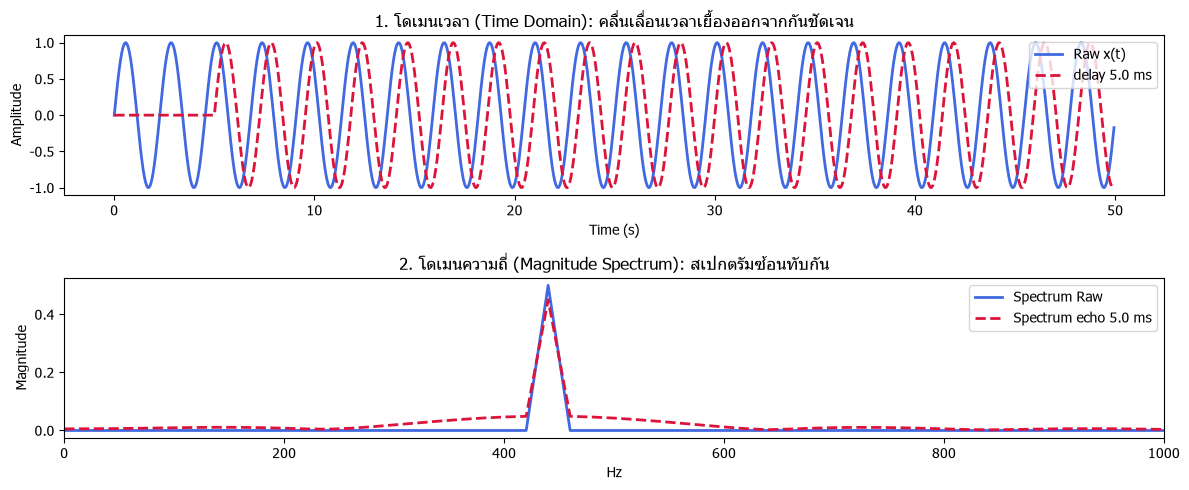

In [2]:
fs = 16000           
duration = 0.05
t = time_axis(fs, duration)
raw = generate_sine(440,t)
echo = generate_sine(440,t)
delay_ms = 5.0
delay_samples = int(fs * delay_ms / 1000.0)
echo = np.zeros_like(raw)
echo[delay_samples:] = raw[:-delay_samples]

N = len(raw)
freqs = np.fft.rfftfreq(N, d=1/fs)
mag_raw = np.abs(np.fft.rfft(raw)) / N
mag_echo = np.abs(np.fft.rfft(echo)) / N


plt.figure(figsize=(12,5))
plt.subplot(2,1,1)
plt.plot(t * 1000,raw, label="Raw x(t)", color="royalblue", lw=2)
plt.plot(t * 1000, echo, label=f"delay {delay_ms} ms", color="crimson", lw=2, linestyle="--")
plt.title("1. โดเมนเวลา (Time Domain): คลื่นเลื่อนเวลาเยื้องออกจากกันชัดเจน")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend(loc="upper right")
plt.tight_layout()

plt.subplot(2,1,2)
plt.plot(freqs, mag_raw, label="Spectrum Raw", color="royalblue", lw=2)
plt.plot(freqs, mag_echo, label=f"Spectrum echo {delay_ms} ms", color="crimson", lw=2, linestyle="--")
plt.title("2. โดเมนความถี่ (Magnitude Spectrum): สเปกตรัมซ้อนทับกัน")
plt.xlabel("Hz")
plt.ylabel("Magnitude")
plt.legend(loc="upper right")
plt.xlim(0, 1000)
plt.tight_layout()


[Echo Lag] โหมด: กำหนดค่าเอง (Custom) -> ใช้ Lag = 12.00 ms (192 samples)
🎯 ผลการตรวจจับจุดเริ่มต้นของเสียงสะท้อน (Echo Start Point):
   - หน่วงเวลา (Lag Samples) : 192 ตัวอย่าง (Samples)
   - หน่วงเวลา (Delay Time)  : 12.00 มิลลิวินาที (ms)


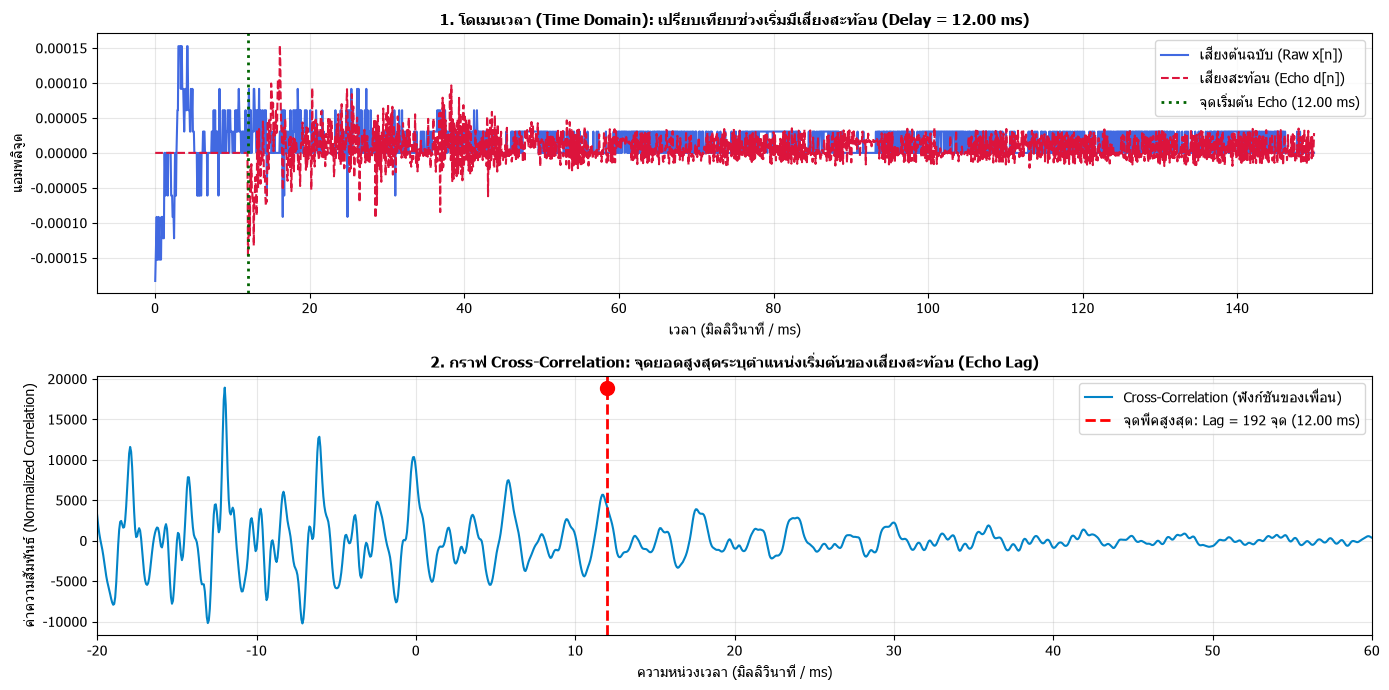

In [3]:
# ==============================================================================
# ค้นหาจุดเริ่มต้นของเสียงสะท้อน (Echo Lag / Delay Detection)
# ==============================================================================
# 1. โหลดเสียงคนพูดจริงและจำลองเสียงสะท้อนผ่านห้อง (S1: กำหนด Delay ไว้ 12 ms)
t, raw, echo, fs = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1, lag_ms=12.0)

# 2. ค้นหาจุดเริ่มต้นของเสียงสะท้อนด้วยฟังก์ชัน correlation_offset ของเพื่อน
search_len = int(fs * 1.5)  # ใช้สัญญาณช่วง 1.5 วินาทีแรกเพื่อความเร็วและความแม่นยำ
corr, lags, best_lag = correlation_offset(raw[:search_len], echo[:search_len])
det_lag = abs(best_lag)
best_lag_ms = (det_lag / fs) * 1000.0

print("=" * 70)
print(f"🎯 ผลการตรวจจับจุดเริ่มต้นของเสียงสะท้อน (Echo Start Point):")
print(f"   - หน่วงเวลา (Lag Samples) : {det_lag} ตัวอย่าง (Samples)")
print(f"   - หน่วงเวลา (Delay Time)  : {best_lag_ms:.2f} มิลลิวินาที (ms)")
print("=" * 70)

# 3. พล็อตกราฟเปรียบเทียบคลื่นเสียงและจุดยอด Cross-Correlation
plt.figure(figsize=(14, 7))

# 3.1 โดเมนเวลา: ดูการเลื่อนเยื้องของเสียง Echo
plt.subplot(2, 1, 1)
zoom_n = int(fs * 0.15)  # ซูมดูช่วง 150 ms แรกเพื่อเห็นจุดเริ่มชัดเจน
t_zoom = t[:zoom_n] * 1000.0
plt.plot(t_zoom, raw[:zoom_n], color="royalblue", lw=1.5, label="เสียงต้นฉบับ (Raw x[n])")
plt.plot(t_zoom, echo[:zoom_n], color="crimson", lw=1.5, linestyle="--", label="เสียงสะท้อน (Echo d[n])")
plt.axvline(best_lag_ms, color="darkgreen", lw=2, linestyle=":", label=f"จุดเริ่มต้น Echo ({best_lag_ms:.2f} ms)")
plt.title(f"1. โดเมนเวลา (Time Domain): เปรียบเทียบช่วงเริ่มมีเสียงสะท้อน (Delay = {best_lag_ms:.2f} ms)", fontsize=11, fontweight="bold")
plt.xlabel("เวลา (มิลลิวินาที / ms)")
plt.ylabel("แอมพลิจูด")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

# 3.2 กราฟ Normalized Cross-Correlation หาจุดยอด (Peak)
plt.subplot(2, 1, 2)
lags_ms = (lags / fs) * 1000.0
plt.plot(lags_ms, corr, color="#0284c7", lw=1.5, label="Cross-Correlation (ฟังก์ชันของเพื่อน)")
plt.axvline(best_lag_ms, color="red", linestyle="--", lw=2, label=f"จุดพีคสูงสุด: Lag = {det_lag} จุด ({best_lag_ms:.2f} ms)")
plt.scatter([best_lag_ms], [corr[np.argmax(corr)]], color="red", s=100, zorder=5)
plt.xlim(-20, 60)
plt.title("2. กราฟ Cross-Correlation: จุดยอดสูงสุดระบุตำแหน่งเริ่มต้นของเสียงสะท้อน (Echo Lag)", fontsize=11, fontweight="bold")
plt.xlabel("ความหน่วงเวลา (มิลลิวินาที / ms)")
plt.ylabel("ค่าความสัมพันธ์ (Normalized Correlation)")
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
